In [1]:
import pyC2C as c2c
import matplotlib.pyplot as plt
import pandas as pd

### Load source data and results data frame

In [ ]:
# load fid or ms data
raw_data = c2c.load_file('sample_data/shimadzu_C2C005.qgd')
raw_data.getBPC() 

paraffins = c2c.load_file('sample_data/shimadzu_paraffins.qgd')
paraffins.getBPC()

0
10000
20000
30000
40000
50000
60000
70000
80000
90000
100000
Number of MS1 scans: 106680
0
10000
20000
30000
40000
50000
60000
70000
80000
90000
100000
Number of MS1 scans: 102480


In [ ]:
results_df = pd.read_csv('sample_data/C2C-005_results.csv', sep=',')
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z)
0,6.1158,6.10,1.95,21049.0,1,66.05:7.42 67.0:6.38 67.1:25.33 67.15:9.37 67....,103.10,-1
1,6.0708,6.03,3.25,6014.0,2,65.0:25.09 66.0:20.43 66.1:8.64 67.1:50.38 68....,203.00,15
2,9.5858,9.57,2.15,26802.0,3,63.0:5.04 65.0:14.04 66.0:5.91 66.1:6.08 66.15...,127.20,9
3,9.7208,9.70,2.25,13021.0,4,65.0:14.3 66.1:5.15 66.15:13.88 66.2:5.51 66.2...,127.15,9
4,10.0542,10.03,2.25,82421.0,5,65.0:6.14 66.0:7.06 67.05:5.31 67.1:8.11 67.2:...,127.20,9


### Get dictionary of RT for paraffins

In [4]:
lri_calculator = c2c.LinearRetentionIndex()
lri_calculator.print_LRIList()

7 : 7.0
8 : 9.13
9 : 12.67
10 : 17.4
11 : 22.67
12 : 27.93
13 : 32.87
14 : 37.6
15 : 41.93


In [5]:
# change or add item to dictionary
lri_calculator.add_to_LRIList(carbon_number=6,
                              retention_time=6.0)

6 : 6.0
7 : 7.0
8 : 9.13
9 : 12.67
10 : 17.4
11 : 22.67
12 : 27.93
13 : 32.87
14 : 37.6
15 : 41.93


### Plot paraffins and sample

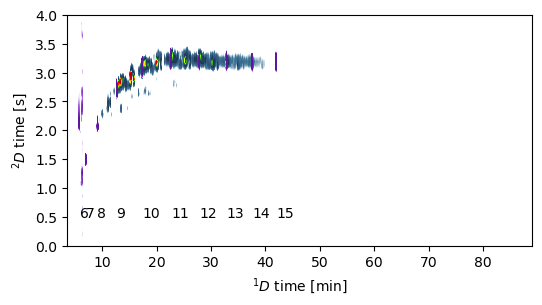

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))

c2c.plot2d(fig, ax, raw_data.rt, raw_data.bpc, 4, shift=1, cbar=False, color_range=(8, 80))
c2c.plot2d(fig, ax, paraffins.rt, paraffins.bpc, 4, shift=-1, cbar=False, color_range=(10, 20), cmap=c2c.cmaps.purples)

ax.set_xlim()
ax.set_ylim()

# ax.grid()

# print Carbon Number of Paraffins
for k in lri_calculator.lri_dict.keys():
    ax.text(x=lri_calculator.lri_dict[k], y= 0.5, s=k, fontdict=dict({'fontsize' : 10}))

plt.show()

### Calculate LRI and add to data frame

In [7]:
results_df['LRI'] = lri_calculator.getLRI_list(results_df['RT 1d (min)'].values)
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z),LRI
0,6.1158,6.10,1.95,21049.0,1,66.05:7.42 67.0:6.38 67.1:25.33 67.15:9.37 67....,103.10,-1,610
1,6.0708,6.03,3.25,6014.0,2,65.0:25.09 66.0:20.43 66.1:8.64 67.1:50.38 68....,203.00,15,603
2,9.5858,9.57,2.15,26802.0,3,63.0:5.04 65.0:14.04 66.0:5.91 66.1:6.08 66.15...,127.20,9,812
3,9.7208,9.70,2.25,13021.0,4,65.0:14.3 66.1:5.15 66.15:13.88 66.2:5.51 66.2...,127.15,9,816
4,10.0542,10.03,2.25,82421.0,5,65.0:6.14 66.0:7.06 67.05:5.31 67.1:8.11 67.2:...,127.20,9,825


In [ ]:
# export data frame
results_df.to_csv('sample_data/C2C-005_results.csv', sep=',', index=False)